In [1]:
import squigglepy as sq

from datetime import datetime
from pprint import pprint

from libs import run_model, plot_exponential_growth, analyze_agi_arrival, calculate_doubling_time
from model_params_ai_rd import start_task_length, agi_task_length, doubling_time, shift, current_best_date

print("Loaded libraries")

Loaded libraries


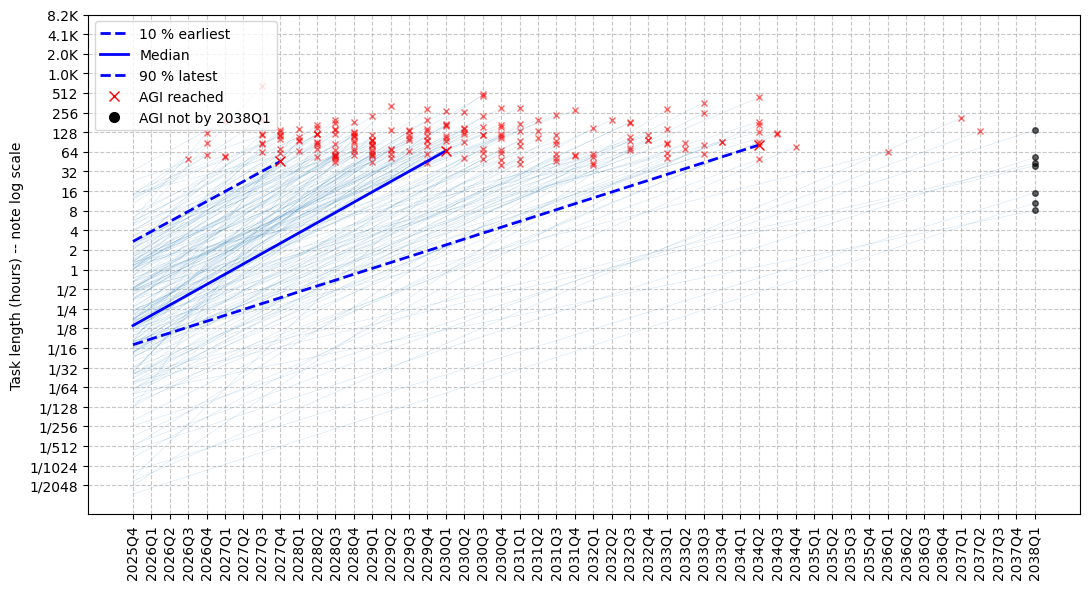

In [2]:
plot_exponential_growth(
    doubling_time_days=doubling_time,
    start_hours=start_task_length,
    start_date=current_best_date,
    agi_task_length=agi_task_length,
    shift=shift,
    n_quarters=49,
    n_samples=100_000,
    n_traces=200,
    max_task_power=13,
    min_y_power=-15,
)
# TODO: Add compute bend
# TODO: Use AI R&D automation to add superexponential

In [3]:
def adapted_metr_model():
    start_task_length_ = start_task_length * (2 ** (shift / doubling_time))
    days = calculate_doubling_time(start_task_length_, agi_task_length, doubling_time)
    measurement_error_variance = sq.invlognorm(0.8, 1.5) # Add measurement error on tasks: SD fit to trend variance from Figure 12
    return days * measurement_error_variance

samples = run_model(adapted_metr_model, index_date=current_best_date, cores=4)
print('\n\n')
analyze_agi_arrival(samples)

Generating samples with 4 cores...


100%|███████████████████████████████████████████████████████████████████████████| 100000/100000 [00:24<00:00, 4048.75it/s]


Shuffling data...
Waiting for other cores...


100%|█████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 1622.24it/s]


...Collected!
{1: 238,
 5: 556,
 10: 729,
 20: 985,
 30: 1195,
 40: 1411,
 50: 1640,
 60: 1903,
 70: 2207,
 80: 2622,
 90: 3329,
 95: 4024,
 99: 5722}

-

{1: '2026 Aug 06',
 5: '2027 Jun 20',
 10: '2027 Dec 11',
 20: '2028 Aug 22',
 30: '2029 Mar 21',
 40: '2029 Oct 22',
 50: '2030 Jun 08',
 60: '2031 Feb 27',
 70: '2031 Dec 28',
 80: '2033 Feb 15',
 90: '2035 Jan 23',
 95: '2036 Dec 18',
 99: '2041 Aug 12'}



## DISTRIBUTION OF AGI ARRIVAL DATE ##
1%: 2025.7
2%: 2026.0
3%: 2026.2
4%: 2026.4
5%: 2026.5
10%: 2027.0
15%: 2027.4
20%: 2027.7
25%: 2028.0
35%: 2028.6
50%: 2029.5
60%: 2030.2
75%: 2031.6
80%: 2032.2
90%: 2034.1
95%: 2036.0


## DISTRIBUTION OF RELATIVE AGI ARRIVAL DATE ##
1%: 0.7 years from now
2%: 1.0 years from now
3%: 1.2 years from now
4%: 1.4 years from now
5%: 1.5 years from now
10%: 2.0 years from now
15%: 2.4 years from now
20%: 2.7 years from now
25%: 3.0 years from now
35%: 3.6 years from now
50%: 4.5 years from now
60%: 5.2 years from now
75%: 6.6 years from now
8

In [4]:
samples

array([1226.15008936,  883.58821833, 1345.19721868, ..., 1405.37002553,
       1255.69296368, 1819.0867377 ])